# 9.A.1. Деревья и экстраполяция (sktime, AirPassengers)

Градиентный бустинг — это не «улучшенная линейная регрессия». У него есть одна системная
**слабость**: дерево не экстраполирует. Лист дерева — среднее target по попавшим в него
объектам train, поэтому уровня выше максимума train модель выдать не может.

Сквозной вопрос ноутбука: **откуда модель узнает уровень ряда в будущем, если такого уровня
не было в train?**

Идём шаг за шагом по одному и тому же ряду и на каждом шаге сравниваем `CatBoostRegressor`
с `LinearRegression` на тех же признаках:

1. признаки только из времени (год, месяц);
2. только месяц;
3. удаление тренда;
4. удаление сезонности и тренда;
5. лаги вместо календаря;
6. ловушка: логарифм + линейный тренд.

In [1]:
import common  # первым: глушит предупреждения библиотек при импорте

common.quiet()

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
from catboost import CatBoostRegressor  # noqa: E402
from sklearn.linear_model import LinearRegression  # noqa: E402
from sktime.forecasting.compose import (  # noqa: E402
    ForecastingPipeline,
    TransformedTargetForecaster,
    YfromX,
    make_reduction,
)
from sktime.forecasting.naive import NaiveForecaster  # noqa: E402
from sktime.forecasting.trend import PolynomialTrendForecaster  # noqa: E402
from sktime.split import temporal_train_test_split  # noqa: E402
from sktime.transformations.series.boxcox import LogTransformer  # noqa: E402
from sktime.transformations.series.date import DateTimeFeatures  # noqa: E402
from sktime.transformations.series.detrend import Deseasonalizer, Detrender  # noqa: E402

from common import mape, plot_forecast  # noqa: E402

## 0. Постановка

Месячные авиаперевозки 1949–1960. Растущий тренд и **мультипликативная** сезонность:
амплитуда летнего пика растёт вместе с уровнем. Прогнозируем последние 3 года (H = 36),
как в исходном ноутбуке 9.1.1.

train: 1949-01 … 1957-12 (108 точек)
test:  1958-01 … 1960-12 (36 точек)
максимум train = 467, максимум test = 622


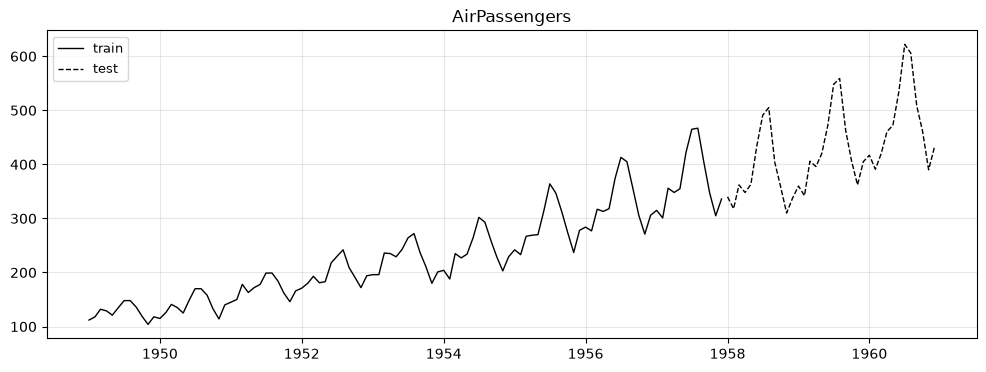

In [2]:
H = 36
y = common.load_airpassengers()
y_train, y_test = temporal_train_test_split(y, test_size=H)
fh = np.arange(1, H + 1)

print(f"train: {y_train.index[0]} … {y_train.index[-1]} ({len(y_train)} точек)")
print(f"test:  {y_test.index[0]} … {y_test.index[-1]} ({len(y_test)} точек)")
print(f"максимум train = {y_train.max():.0f}, максимум test = {y_test.max():.0f}")

ax = plot_forecast(y_train, y_test, {}, title="AirPassengers")

Максимум теста заметно выше максимума train — именно такого уровня дерево никогда не видело.

Бейзлайн — сезонный наивный прогноз: «повторить последний год». Любая модель ниже должна
его обгонять, иначе она не нужна.

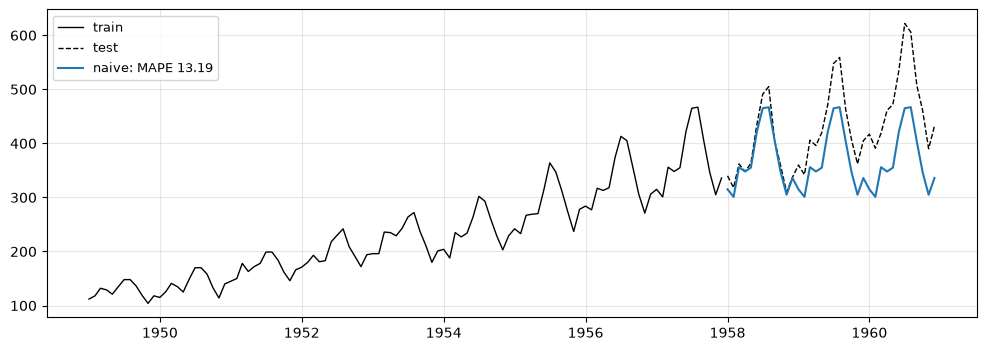

In [3]:
naive = NaiveForecaster(strategy="last", sp=12).fit(y_train, fh=fh)
results = {"naive (последний год)": {"CatBoost": mape(y_test, naive.predict()), "Linear": np.nan}}
plot_forecast(y_train, y_test, {"naive": naive.predict()});

### Единый конструктор прогнозатора

Каждый шаг ноутбука — это один и тот же sktime-пайплайн с разными «кубиками»:

- `TransformedTargetForecaster([...трансформации target..., модель])` — трансформирует `y` перед
  обучением и автоматически делает обратное преобразование прогноза (`inverse_transform`);
- `ForecastingPipeline([DateTimeFeatures, YfromX(reg)])` — строит календарные признаки из индекса
  и обучает на них обычный табличный регрессор.

**Ловушка sktime**: признаки из `DateTimeFeatures` строятся из `X`, а не из `y`. Если не
передать в `fit`/`predict` хотя бы пустую таблицу `X` с нужным индексом, трансформация
не вызывается, модель обучается без признаков и прогнозирует константу (среднее train).
Ошибки при этом нет.

In [4]:
X = pd.DataFrame(index=y.index)  # пустая таблица: нужна только как носитель индекса
X_train, X_test = X.loc[y_train.index], X.loc[y_test.index]

REGRESSORS = {
    "CatBoost": lambda: CatBoostRegressor(iterations=500, depth=4, random_seed=0, verbose=False),
    "Linear": LinearRegression,
}


def make_forecaster(reg, features, detrend=False, deseason=False, log=False):
    """Пайплайн: [log] → [снятие сезонности] → [снятие тренда] → календарь → регрессор."""
    steps = []
    if log:
        steps.append(LogTransformer())
    if deseason:
        steps.append(Deseasonalizer(sp=12, model="multiplicative"))
    if detrend:
        steps.append(Detrender(forecaster=PolynomialTrendForecaster(degree=1)))
    features = DateTimeFeatures(ts_freq="M", manual_selection=features)
    steps.append(ForecastingPipeline([features, YfromX(reg)]))
    return TransformedTargetForecaster(steps)


def run(name, **kwargs):
    """Обучить вариант с обоими регрессорами, записать MAPE в `results`, вернуть прогнозы."""
    preds = {}
    for reg_name, reg in REGRESSORS.items():
        f = make_forecaster(reg(), **kwargs).fit(y_train, X=X_train, fh=fh)
        preds[reg_name] = f.predict(X=X_test)
    results[name] = {reg_name: mape(y_test, p) for reg_name, p in preds.items()}
    plot_forecast(y_train, y_test, preds, title=name)
    return preds

## 1. Признаки — только время: год и месяц

In [5]:
DateTimeFeatures(ts_freq="M", manual_selection=["year", "month_of_year"]).fit_transform(X_train).head(3)

,year,month_of_year
Month,,
1949-01,1949,1
1949-02,1949,2
1949-03,1949,3


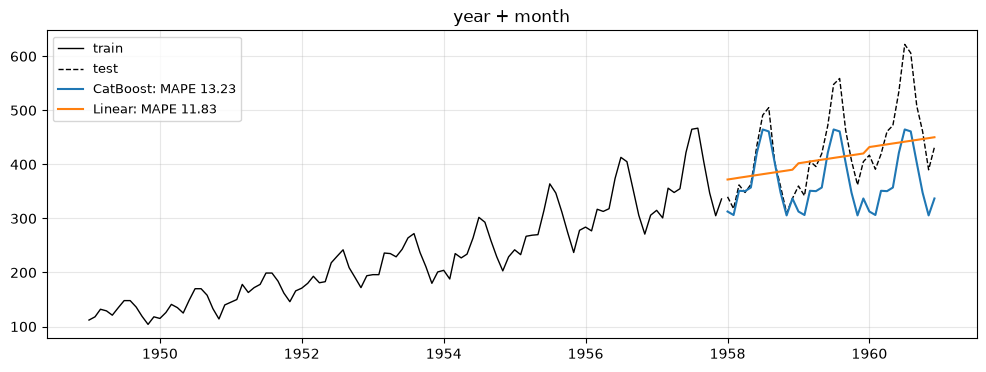

In [6]:
run("year + month", features=["year", "month_of_year"]);

- **CatBoost** выдаёт «ступеньку»: весь тест прогнозируется на уровне последнего года train.
  Все значения `year` в тесте (1958–1960) больше любого в train, и дерево отправляет их в тот же
  лист, что и 1957 год.
- **Linear** продолжает тренд (коэффициент при `year`), но сезонность не ловит: `month_of_year`
  для неё — просто число 1…12, и по нему выучивается только наклон внутри года.

### Почему так: дерево — кусочно-постоянная функция

Самый простой пример: `y = t` без шума, единственный признак — `t`.

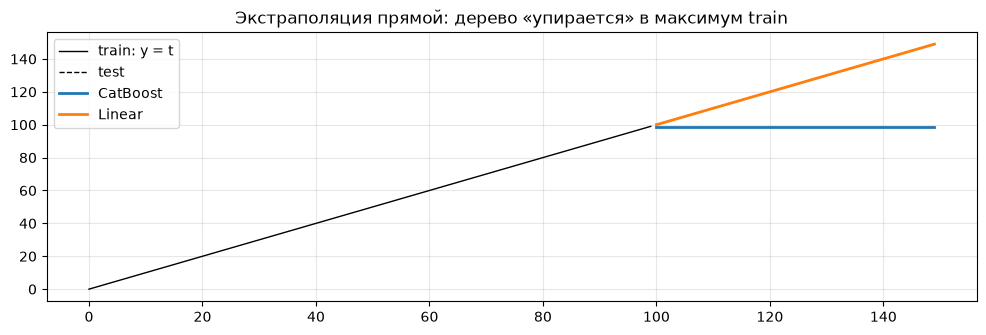

In [7]:
t_train, t_test = np.arange(100), np.arange(100, 150)
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(t_train, t_train, color="black", lw=1, label="train: y = t")
ax.plot(t_test, t_test, color="black", lw=1, ls="--", label="test")
for reg_name, reg in REGRESSORS.items():
    model = reg().fit(t_train.reshape(-1, 1), t_train)
    ax.plot(t_test, model.predict(t_test.reshape(-1, 1)), lw=2, label=reg_name)
ax.legend()
ax.grid(alpha=0.3)
ax.set_title("Экстраполяция прямой: дерево «упирается» в максимум train");

Любой новый `t > 99` попадает в самый правый лист каждого дерева, а значение листа — среднее
по самым правым объектам train. Сумма деревьев ансамбля так и остаётся кусочно-постоянной.

## 2. Календарь без тренда: только месяц

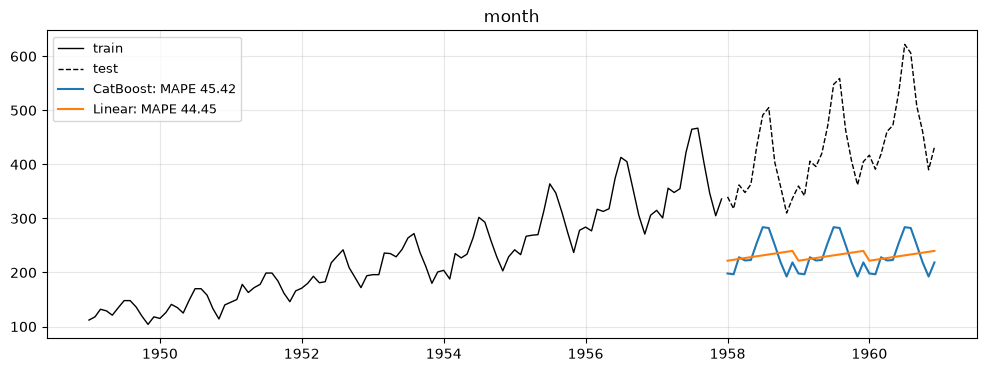

In [8]:
run("month", features=["month_of_year"]);

Форма сезона есть, но уровень — среднее по всему train (1949–1957), поэтому прогноз сильно
ниже реальности. Вывод: **календарь даёт форму сезона, но не уровень ряда**.

## 3. Удаление тренда

Лекарство — убрать тренд до модели: оценить его линейной моделью, вычесть, обучить бустинг на
остатке, а на прогнозе прибавить продолженный тренд. Сначала сделаем это руками — так видно,
что происходит внутри.

In [9]:
t = np.arange(len(y)).reshape(-1, 1)
t_tr, t_te = t[: len(y_train)], t[len(y_train) :]
month_tr = y_train.index.month.to_numpy().reshape(-1, 1)
month_te = y_test.index.month.to_numpy().reshape(-1, 1)

trend = LinearRegression().fit(t_tr, y_train)  # 1) обучили тренд
resid = y_train - trend.predict(t_tr)  # 2) вычли
booster = REGRESSORS["CatBoost"]().fit(month_tr, resid)  # 3) бустинг на остатке по месяцу
manual = trend.predict(t_te) + booster.predict(month_te)  # 4) вернули тренд
print(f"руками: MAPE = {mape(y_test, manual):.2f}")

руками: MAPE = 7.09


В sktime эти четыре строки — один шаг `Detrender(PolynomialTrendForecaster(degree=1))`:
на `fit` он обучает тренд и вычитает его, на `predict` — прибавляет обратно.

sktime: MAPE = 7.09


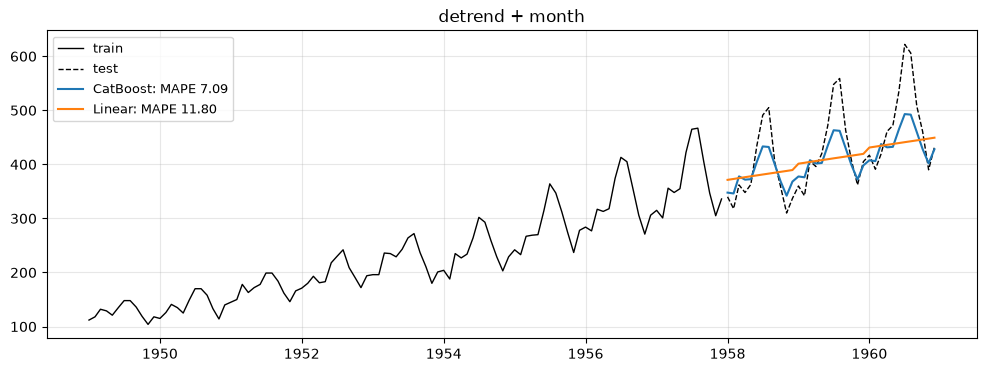

In [10]:
detrended = run("detrend + month", features=["month_of_year"], detrend=True)
print(f"sktime: MAPE = {mape(y_test, detrended['CatBoost']):.2f}")

Теперь бустинг заметно лучше линейной модели. Причина — в остатке. После вычитания
**линейного** тренда остаётся мультипликативная сезонность: летний пик в 1957 году больше,
чем в 1949-м. Посмотрим на остаток и на то, что из него выучили модели.

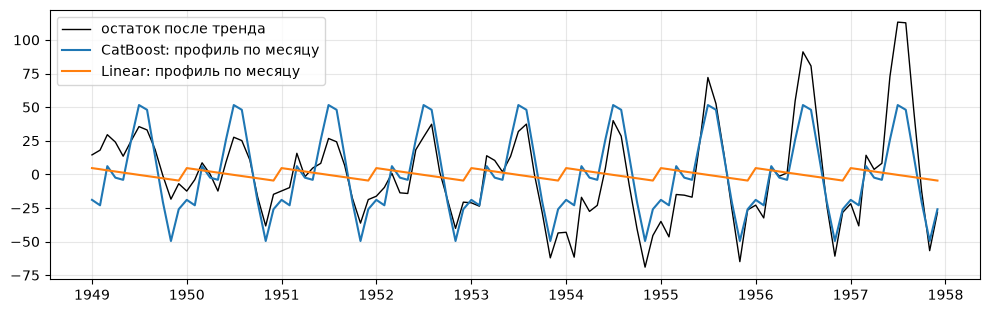

In [11]:
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(y_train.index.to_timestamp(), resid, color="black", lw=1, label="остаток после тренда")
for reg_name, reg in REGRESSORS.items():
    fitted = reg().fit(month_tr, resid).predict(month_tr)
    ax.plot(y_train.index.to_timestamp(), fitted, lw=1.5, label=f"{reg_name}: профиль по месяцу")
ax.legend()
ax.grid(alpha=0.3);

`LinearRegression` по числовому признаку `month` может выучить только **наклон**: «каждый следующий
месяц на столько-то больше». Дерево по тому же признаку выучивает сезонный профиль любой формы.
(С one-hot месяцем линейная модель тоже выучит профиль, но всё равно одной амплитуды.)

## 4. Удаление сезонности и тренда

Раз сезонность мультипликативная, её можно снять отдельно: `Deseasonalizer(model="multiplicative")`
делит ряд на сезонный индекс (классическое разложение `seasonal_decompose`). В 9.1.1 для этого
понадобились `seasonal_decompose` и `np.roll` — здесь одна строка.

Порядок важен: сначала сезонность, потом тренд. После вычитания тренда остаток бывает
отрицательным, а мультипликативное разложение для таких значений не определено.

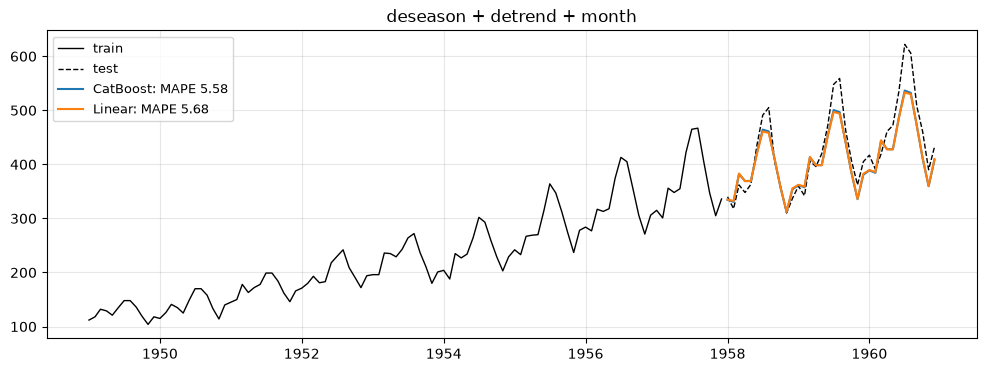

In [12]:
run("deseason + detrend + month", features=["month_of_year"], detrend=True, deseason=True);

После снятия и тренда, и сезонности модели почти нечего делать, поэтому CatBoost и Linear
сравнялись: вся работа сделана трансформациями.

## 5. Лаги вместо календаря

Второй способ «сообщить» модели уровень ряда — лаговые признаки: последние 12 значений.
`make_reduction(..., strategy="recursive")` обучает модель на шаг вперёд, а на прогнозе подставляет
собственные прогнозы вместо неизвестных значений (подробно о стратегиях — блок 3).

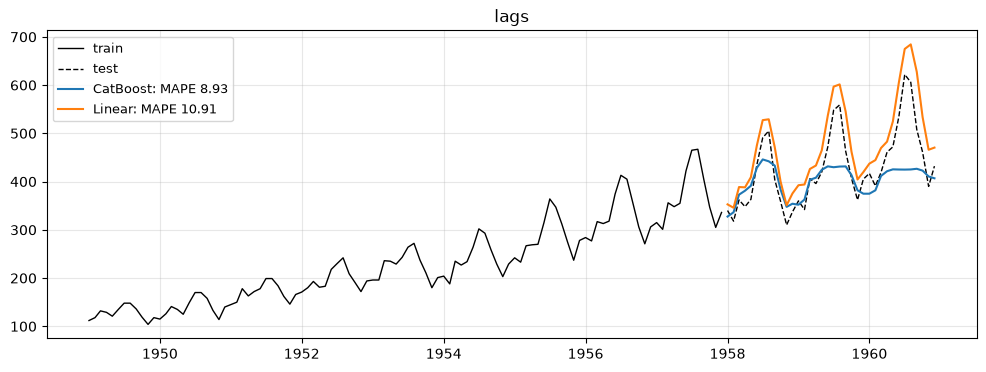

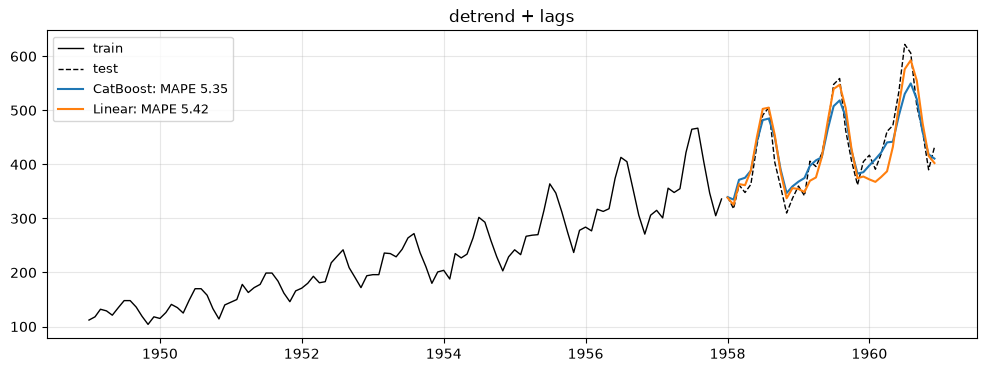

In [13]:
lag_preds = {}
for reg_name, reg in REGRESSORS.items():
    for detrend in (False, True):
        forecaster = make_reduction(reg(), strategy="recursive", window_length=12)
        if detrend:
            forecaster = TransformedTargetForecaster(
                [Detrender(forecaster=PolynomialTrendForecaster(degree=1)), forecaster]
            )
        name = "detrend + lags" if detrend else "lags"
        lag_preds.setdefault(name, {})[reg_name] = forecaster.fit(y_train, fh=fh).predict()

for name, preds in lag_preds.items():
    results[name] = {reg_name: mape(y_test, p) for reg_name, p in preds.items()}
    plot_forecast(y_train, y_test, preds, title=name)

- Без детрендинга лаги помогают: модель видит свежий уровень. Но рекурсия упирается в ту же
  проблему — каждый следующий шаг строится на прогнозах, а прогноз дерева не может выйти выше train,
  поэтому рост постепенно «гаснет».
- С детрендингом лаговая модель — одна из лучших в ноутбуке.

## 6. Ловушка: логарифм + линейный тренд

Мультипликативную сезонность часто лечат логарифмом: в логе она становится аддитивной.
Добавим `LogTransformer` перед удалением тренда.

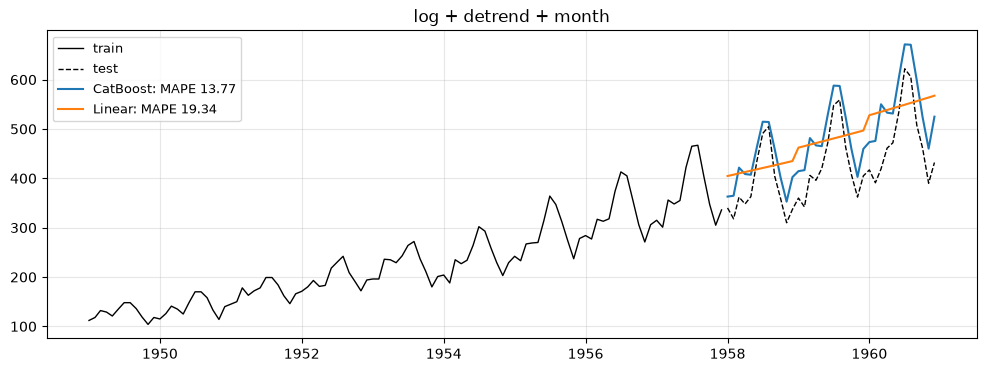

In [14]:
run("log + detrend + month", features=["month_of_year"], detrend=True, log=True);

Стало хуже, причём у обеих моделей. В логарифме линейный тренд — это **экспоненциальный** рост
в исходной шкале. В 1949–1957 рост был быстрым, к 1958–1960 он замедлился, и экспонента на три
года вперёд перелетает реальность.

Детрендинг — это сильное допущение о будущем: модель тренда экстраполируется на весь горизонт.
Если тренд ломается, его надо оценивать по последнему участку (`ChangePointsTrendTransform`
из сем. 7). Ещё одно лекарство — linear trees (`linear_tree=True` в LightGBM): в листьях не
константа, а линейная модель, поэтому дерево экстраполирует само (лонгрид, §3.3).

## 7. Итоги

In [15]:
summary = pd.DataFrame(results).T.round(2)
summary

,CatBoost,Linear
naive (последний год),13.19,NaN
year + month,13.23,11.83
month,45.42,44.45
detrend + month,7.09,11.80
deseason + detrend + month,5.58,5.68
lags,8.93,10.91
detrend + lags,5.35,5.42
log + detrend + month,13.77,19.34


1. **Деревья не экстраполируют** — уровень ряда, которого не было в train, надо дать модели
   извне: убрать тренд трансформацией (шаги 3–4) или подать свежий уровень лагами (шаг 5).
2. **После детрендинга бустинг выигрывает за счёт нелинейности**: он ловит мультипликативную
   сезонность, которую линейная модель с аддитивным месяцем не видит.
3. **На одном коротком ряде выигрыш хрупкий**: 108 точек train, после хорошей предобработки
   линейная модель догоняет бустинг. Сила бустинга — в сотнях рядов и одной общей модели
   (ноутбук 9.A.3).